In [55]:
import duckdb
import pandas as pd

database_connection = duckdb.connect()
DATA_PATH = "../data/creditcard.csv"
query = f"CREATE OR REPLACE TABLE transactions AS SELECT * FROM read_csv_auto('{DATA_PATH}')"
database_connection.execute(query)

def q(sql): #helper function for executing sql queries
    return database_connection.execute(sql).df()

q("SELECT * FROM transactions LIMIT 5")


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [56]:
#Missing values across every column
df = q("SELECT * FROM transactions")
rows_before = len(df)
print(f"Rows before cleaning up the data: {rows_before:,}")
print("Total missing values across every column:", df.isna().sum().sum())

# Exact duplicate rows
n_duplicates = df.duplicated().sum()
print(f"Duplicate rows: {n_duplicates} ({n_duplicates / len(df):.2%} of data)")
counts = df[df.duplicated()]["Class"].value_counts()
print(f"Duplicates by class: {counts[0]} normal, {counts[1]} fraud")

database_connection.execute("CREATE OR REPLACE TABLE transactions AS SELECT DISTINCT * FROM transactions")
rows_after_removing_duplicates = database_connection.execute("SELECT COUNT(*) FROM transactions").fetchone()[0]
print(f"Rows after removing duplicates: {rows_after_removing_duplicates:,}")

df = q("SELECT * FROM transactions")

Rows before cleaning up the data: 284,807
Total missing values across every column: 0
Duplicate rows: 1081 (0.38% of data)
Duplicates by class: 1062 normal, 19 fraud
Rows after removing duplicates: 283,726


### Fraud rate
This grid shows 600 transactions, one square each. On average, only one of them (red) is fraud.

In [89]:
balance = q("""
SELECT
    Class AS normal_0_fraud_1,
    COUNT(*) AS number_of_transactions,
    ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM transactions), 3) AS percentage
FROM transactions
GROUP BY Class
""")
balance

,normal_0_fraud_1,number_of_transactions,percentage
0,0,283253,99.833
1,1,473,0.167


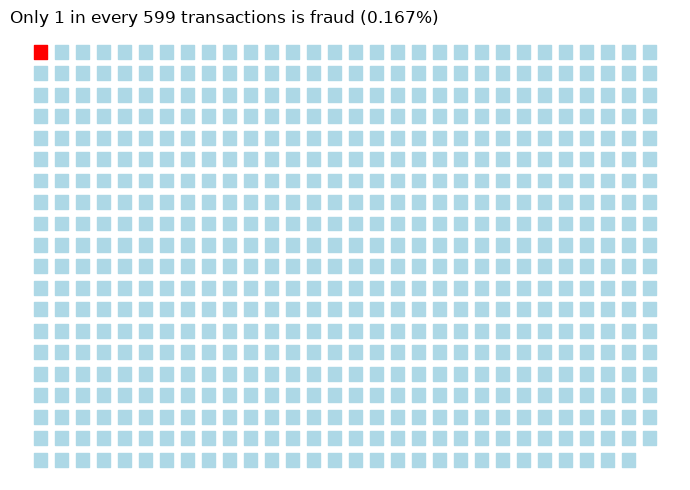

In [90]:
import matplotlib.pyplot as plt

fraud_percentage = balance.loc[balance["normal_0_fraud_1"] == 1, "percentage"].iloc[0]
n_squares = round(100 / fraud_percentage)
cols = 30

x = [i % cols for i in range(n_squares)]
y = [i // cols for i in range(n_squares)]
colors = ["red" if i == 0 else "lightblue" for i in range(n_squares)]

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x, y, c=colors, marker="s", s=100)
ax.invert_yaxis()
ax.axis("off")
ax.set_title(f"Only 1 in every {n_squares} transactions is fraud ({fraud_percentage}%)", loc="left")
plt.tight_layout()
plt.savefig("../images/class_balance.png", dpi=150)
plt.show()